# Übungsblatt 2 in "Mechanistische Effektmodellierung" 2026: Bayesian Inference und Markov-Chain-Monte-Carlo

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import scipy.stats.distributions as dist
import scipy
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

## Aufgabe 1: Eigene MCMC-Funktion  
Als eine der simpelsten möglichen Varianten eines MCMC-Algorithmus sollen Sie für diese Aufgabe eine Variante eines Random-Walk-Metropolis-Samplers implementieren und testen.

In diesem kostenlos abrufbaren E-Book finden Sie eine Erklärung, falls Sie noch mal nachlesen wollen:  
Gelman et al., Bayesian Data Analysis (3rd ed.), Section 11.2.  
https://sites.stat.columbia.edu/gelman/book/BDA3.pdf

Implementieren Sie die unten in Pseudo-Code beschriebene Variante des Random-Walk-Metropolis-Samplers. Der Algorithmus soll generell sein (für verschiedene Aufgaben funktionieren) und folgende Argumente enthalten:  
 
- eine Funktion, welche die gesuchte Zieldichte zurückgibt. Sie bekommt zuerst alle Argumente, die sie außer den Parametern braucht (z.B. die beobachteten Daten und die Zeitpunkte), und danach eine beliebige Menge an Parametern  
- die Argumente der Zieldichte (alles außer den Parametern) als Tupel. Ihr Algorithmus rechnet nicht selbst damit, sondern gibt sie nur an die Zieldichte weiter
- eine Funktion, welche für jeden Parameter einen Initialwert wählt und zurückgibt
- die Anzahl an Schritten, die die Markov-Chain gehen soll
- die Schrittweiten pro Parameter, also die Standardabweichungen der Normalverteilungen, aus denen der neue Vorschlag generiert wird
- wie viele Samples am Anfang der Kette als Burn-in weggeworfen werden
  
z.B.:
``` python
def mcmc_simple_own(target_density, target_density_args, initial_state_func, num_steps, stepsize, burn_in):
```
#### Pseudocode: Random-Walk-Metropolis

Nach Gelman et al. (BDA3, Abschnitt 11.2), aber etwas vereinfacht.

```
Schritt 1: Startpunkt
    wähle Startwerte für alle Parameter (die Posterior-Dichte muss dort größer als 0 sein)
    speichere den Startpunkt als ersten Eintrag der Kette

Schritt 2: wiederhole sehr oft:

    (a) Vorschlag:
        gehe vom aktuellen Punkt aus einen kleinen, zufälligen Schritt
        (für jeden Parameter eine normalverteilte Zufallszahl mit der gewählten Schrittweite)

    (b) Vergleich:
        berechne, wie viel plausibler der Vorschlag ist als der aktuelle Punkt
        (Verhältnis der Posterior-Dichten von Vorschlag und aktuellem Punkt)

    (c) Entscheidung:
        ist die Posterior-Dichte des Vorschlags NaN, wird er immer abgelehnt (der aktuelle Punkt bleibt)
        ist der Vorschlag plausibler, wird er immer angenommen
        ist er weniger plausibel, wird er nur manchmal angenommen, und zwar umso seltener,
            je schlechter er ist (z. B. halb so plausibel → in der Hälfte der Fälle)
        angenommen → der Vorschlag wird der neue aktuelle Punkt
        abgelehnt  → der aktuelle Punkt bleibt

    speichere den aktuellen Punkt in der Kette (auch nach einer Ablehnung)

Ende:
    verwirf die ersten Schritte der Kette (Burn-in)
    der Rest der Kette ist die Stichprobe aus der Posterior
```

**Hinweise**
- Die Zieldichte-Funktionen in diesem Übungsblatt geben nicht die Dichte selbst zurück, sondern ihren Logarithmus (log-Dichte). Das ist in der Praxis üblich, weil die Dichten selbst so kleine Zahlen werden können, dass der Computer sie nicht mehr von 0 unterscheiden kann. Überlegen Sie deshalb, wie Sie das Verhältnis der Posterior-Dichten aus Schritt (b) berechnen können, wenn Sie nur die log-Dichten kennen, ohne dabei mit so kleinen Zahlen rechnen zu müssen. Die Logarithmusgesetze helfen dabei.
- Die Zieldichte gibt NaN zurück, wenn ein Vorschlag nicht erlaubt ist, z. B. weil ein Parameter negativ ist. Solche Vorschläge müssen Sie abfangen (z. B. mit ```np.isnan()```), denn mit NaN kann nicht sinnvoll gerechnet werden: Jede Rechnung mit NaN ergibt wieder NaN, und Vergleiche wie ```<``` oder ```>``` mit NaN ergeben immer ```False```. Je nachdem, wie Sie die Entscheidung programmieren, wird ein solcher Vorschlag sonst angenommen (z. B. gibt ```min(1, np.nan)``` in Python 1 zurück). Ab dann ist die Dichte des aktuellen Punktes NaN, jeder weitere Vorschlag wird angenommen und die Kette läuft ziellos durch den Parameterraum.
- Die Schrittweite (Standardabweichung der Normalverteilung, aus der der Vorschlag generiert wird) entscheidet, wie gut die Kette funktioniert: Ist sie zu klein, kommt die Kette kaum voran und kann steckenbleiben. Ist sie zu groß, wird fast jeder Vorschlag abgelehnt. Unten werden sinnvolle Werte vorgegeben.
- Mit ```*``` können Sie ein Tupel oder eine Liste beim Funktionsaufruf in einzelne Argumente entpacken, z. B. ist ```f(*(1, 2), 3)``` dasselbe wie ```f(1, 2, 3)```.
- Mit ```tqdm``` (ist oben schon importiert) können Sie sich für Schleifen mit vielen Schritten einen Fortschrittsbalken anzeigen lassen. So sehen Sie, wie lange ein Lauf noch dauert. Dokumentation: https://tqdm.github.io/

In [2]:
# Lösung

def random_walk_metro(target_density, target_density_args, initial_state_func, num_steps, stepsize, burn_in):
    """
    target_density: fnction that calculates how good the new params are,
    target_density_args: arguments of tar_den, in a touple like data, time_Data

    initial_state_func: function that generates an array of start parameter

    num_steps: wieviele steps in chain
    stepsize: self explanatory (standardabweichung de rnormalverteilung)
    burn_in: deleted samples at start chain bec to find good params
    """
    #get start parameter set, get them as array so we can add them later
    current = np.asarray(initial_state_func(), dtype=float)
    #get the log of the posterior density
    current_logp = target_density(*target_density_args, *current)

    #check if currentlogp is not Nan or inf bec should be p >0
    if not np.isfinite(current_logp):
        raise ValueError("Wrong start params")

    #empty chain
    chain = np.zeros((len(current), num_steps))
    #save first params
    chain[:, 0] = current

    #now the loop, start with place 1 bec of start values and end at num_steps-1
    for i in range(1, num_steps):
        #do random step
        step = np.random.normal(loc=0, scale=stepsize, size=len(current))
        #cal proposal
        proposal = step + current
        #rate proposal
        proposal_logp = target_density(*target_density_args, *proposal)

        #calc how good the proposal is
        if np.isfinite(proposal_logp):
            log_ratio = proposal_logp - current_logp
            #if proposl is good proposal is the new current
            if log_ratio >= 0:
                current = proposal
                current_logp = proposal_logp
            else:
                #get random value for propability of proposal acceptance
                u = np.random.random()

                #compare and if yes, set proposal to current
                if np.log(u) < log_ratio:
                    current = proposal
                    current_logp = proposal_logp

        #save current, proposal if proposal better than current, current if proposal is nan of inf, and with a propability proposal if proposal is worse
        chain[:, i] = current

    #return with burn in
    return chain[:, burn_in:]

## Aufgabe 2: Testen Sie nun Ihren MCMC-Algorithmus  
Testen Sie Ihren MCMC-Algorithmus, indem Sie versuchen, die logistische Wachstumsfunktion als Differentialgleichung an zufällig generierte Daten zu fitten. Dafür benötigen wir aber noch einige Schritte:  
Die "beobachteten Daten" werden unten schon für Sie generiert. Dort sehen Sie auch die "wahren" Parameterwerte, um zu vergleichen, ob Ihre Funktion die richtigen Werte gefunden hat. Dafür müssen Sie die Differentialgleichung implementieren sowie eine Funktion, in der sie abhängig von einem Zeitvektor, einer Anfangsbedingung und Parameterwerten gelöst wird. Zusätzlich benötigen Sie eine Funktion, in der die Posterior-Wahrscheinlichkeit abhängig von den beobachteten Daten und den Parameterwerten berechnet wird: die Zieldichte. Darin werden mit den Parameterwerten zuerst die vorhergesagten Daten berechnet und dann mit den beobachteten Daten verglichen. Die Priordichte ist schon vorgegeben, ebenso die Likelihood-Funktion. 

### A2a  
Erklären Sie die Likelihood-Funktion. Was bedeutet Likelihood? Wie wird sie hier berechnet?

In [3]:
def logistic_growth_likelihood_function(obs, pred):
    llhs = scipy.stats.norm(obs,2).logpdf(pred)
    return np.sum(llhs)

Antwort:  
Eine Likelihood-Funktion beschreibt, wie gut die Daten x durch die Modellparameter $\theta$ dargestellt werden Mathematisch ausgedrückt als L = ($\theta$;x) = p = (x|$\theta$).
In diesem Fall wird die log-likelihood einer logitic growth für bestimmte Daten bestimmt. Dabei werden der Funktion die Daten für obs, also observation, und die vorhersage des modells für pred, also prediction, übergeben. Zuerst wird dann eine Normalverteilung für jeden Datenpunkt aus den Messdaten mit der Standardabweichung 2 erzeugt. Mit logpdf wird dann für jede normalverteilung geschaut, wei hoch die Normalverteilung des Datenpunkts an dem 
punkt des Predicteten punkts ist. Davon wird dann der logarithmus ausgerechnet. Alle log likelihoods werden zusammen gerechnet und die summe wird returned. 

### A2b  
Erklären Sie die vorgegebene Priordichtefunktion. Was bedeutet Prior-Wahrscheinlichkeit? Wie wird sie hier bestimmt? Warum werden Halbnormalverteilungen mit ```loc=0``` oder bei 0 trunkierte Normalverteilungen verwendet? Warum werden die Priorwahrscheinlichkeiten zusammenaddiert?  

In [4]:
def logistic_growth_prior_probability(y0, r, K):
    y0_prior_prob = scipy.stats.halfnorm(loc = 0, scale=1).logpdf(y0)
    r_prior_prob = scipy.stats.halfnorm(loc = 0, scale=0.3).logpdf(r)
    k_prior_prob = scipy.stats.truncnorm(0,1e10,0,10).logpdf(K)
    return y0_prior_prob + r_prior_prob + k_prior_prob

Antwort:  
Prior Warscheinlichkeit ist die angenommene Warscheinlichkeitsverteilung bevor Daten gesampelt wurden. Sie wird hier aus den Annahmen über die drei Parameter der Warscheinlichkeitsverteilung berechnet.
Alle drei Parameter dürfen nicht null sein. Zusätzlich wird für K auch eine upper bound von 1e10 festgelegt (daher hier truncnorm, da dadurch auch obergrenze festlegbar ist). Es macht keinen Sinn eine Warscheinlichkeit für einen unmöglichen Wert (zb < 0) zu berücksichtigen. Trotzdem soll die warscheinlichkeit für werte nahe 0 am höchsten sein. Daher loc=0
Die drei Parameter werden als Unabhängig voneinander verstanden und deshalb die Log Warscheinlichkeitsdichten wieder aufgrund der Log regeln miteinander addiert.

### A2c  
Implementieren Sie das logistische Wachstum als Differentialgleichung sowie eine Funktion, in der es abhängig von einem Zeitvektor, einer Anfangsbedingung und den Parametern gelöst wird und die Lösung zurückgegeben wird.


In [5]:
# Lösung
#logistic grwoth as dgl

def logistic_growth_dgl(t,y,r,K):
    return r * y * (1 - y / K)

def loese_awp(times, y0 ,r,K):
    #löse anfängliches werte problem :D
    #war nicht sicher, ob wir das nutzen sollen, aber es war schon importiert und ne eigene euler könnte man schnell machen, aber ist sehr ineffizient
    solution = solve_ivp(
        logistic_growth_dgl,
        t_span=(times[0], times[-1]),
        y0=[y0],
        t_eval=times,
        args=(r, K)
    )
    return solution.y[0]

### A2d  
Vervollständigen Sie die Funktion, welche die Zieldichte, also die Posteriorwahrscheinlichkeit des logistischen Wachstums mit gegebenen Parametern und Beobachtungsdaten zurückgibt.


In [6]:
def logistic_growth_posterior_probability(observed, times, y0, r, K):
    prior_prob = logistic_growth_prior_probability(y0, r, K)
    if np.isinf(prior_prob): # Hier werden unendlich kleine log-Wahrscheinlichkeiten abgefangen,
        return np.nan        # weil sie den Algorithmus fehlschlagen lassen.
    predicted = loese_awp(times, y0, r, K)
    llh = logistic_growth_likelihood_function(observed, predicted)
    posterior_prob = prior_prob + llh
    return posterior_prob

Jetzt werden die "beobachteten" Daten generiert. Sie ergeben sich als eine Lösung des logistischen Wachstums mit gegebenen "wahren" Parameterwerten. Die Lösung wird dann mit normalverteiltem "Rauschen" verzerrt. Die fertigen beobachteten Daten liegen in ```data``` und die zugehörigen Zeitpunkte in ```times_data```. 

Sie müssen hier nur noch Ihre Funktion für das logistische Wachstum hinzufügen, damit die Daten generiert werden können.

### A2e  
Generieren Sie verzerrte "Beobachtungsdaten" für das logistische Wachstum, indem Sie unten Ihre Lösungsfunktion für das logistische Wachstum einsetzen. Sonst muss nichts geändert werden.

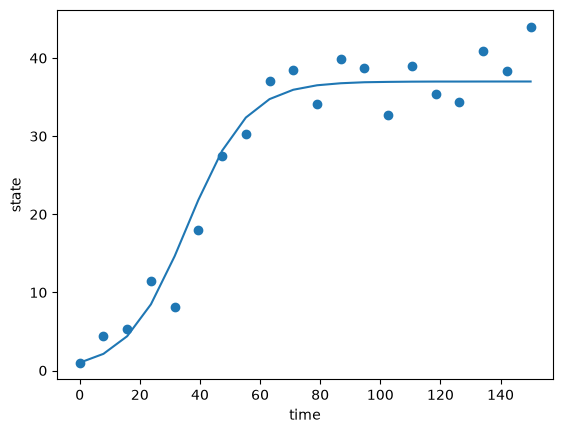

In [7]:
r = 0.1
K = 37
y0 = 1

times_data = np.linspace(0,150,20)
data_clean = loese_awp(times_data, y0, r, K)

data = np.array([data_clean[i] + scipy.stats.norm(0,3).rvs() for i in range(len(data_clean))])
data[0] = 1
data[data<=0] = 0.1

fig, ax = plt.subplots()
ax.scatter(times_data, data)
ax.plot(times_data, data_clean)
ax.set(xlabel='time', ylabel='state')
plt.show()

### A2f  
Zuletzt fehlt noch eine Funktion, mit der der initiale Vorschlag generiert wird. Sie ist schon vorgegeben. Erklären Sie, wie die initialen Vorschläge für die Parameter bestimmt werden.

In [8]:
def initial_state_picker():
    y0 = scipy.stats.halfnorm(loc=0, scale=1).rvs()
    r  = scipy.stats.halfnorm(loc=0, scale=0.3).rvs()
    K  = scipy.stats.truncnorm(0,1e10,0,10).rvs()
    return [y0, r, K]

Antwort:  
Es wird für jeden Parameter ein Wert aus der Halbnormalverteilung, also aus seiner Priorverteilung zufällig gezogen. Diese werden ausgegeben 

### A2g  
Jetzt ist alles da, was benötigt wird. Inferieren Sie nun die Posteriorverteilung mit Ihrer MCMC-Funktion. Wählen Sie 10000 Schritte, einen Burn-in von 3000 und die Schrittweiten ```[0.22, 0.01, 1.17]``` (für y0, r und K). Erstellen Sie einen Trace-Plot pro Parameter. Wenn alles geklappt hat, dann sollten die Kurven permanent auf und ab springen, aber in einem begrenzten Bereich bleiben. Falls nicht, müssen Sie möglicherweise einfach nochmal das Sampling starten. Da der Algorithmus so simpel ist, bleibt er manchmal stecken. Berechnen Sie außerdem den Anteil der angenommenen Vorschläge (Acceptance rate). Sie sollte irgendwo zwischen 10 und 25 % liegen.

In [ ]:
# Lösung
num_steps=10000
burn_in = 3000
stepsize = [0.22, 0.01, 1.17]

#get samples
samples = random_walk_metro(
    target_density=logistic_growth_posterior_probability,
    target_density_args=(data, times_data),
    initial_state_func=initial_state_picker,
    num_steps=num_steps,
    stepsize=stepsize,
    burn_in=burn_in)

#acceptance reate
accepted = 0
anzahl_zustaende = samples.shape[1]

for i in range(1, anzahl_zustaende):
    vorher = samples[:, i - 1]
    nachher = samples[:, i]

    if not np.array_equal(vorher, nachher):
        accepted += 1

acceptance_rate = accepted / (anzahl_zustaende - 1)
print(f"Acceptance rate: {acceptance_rate:.1%}")

#plotting
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for i, name in enumerate(["y0", "r", "K"]):
    axes[i].plot(samples[i], linewidth=0.5)
    axes[i].set_ylabel(name)

axes[-1].set_xlabel("Zustand nach Burn-in")

plt.tight_layout()
plt.show()

### A2h  
Erstellen Sie einen Plot, in dem die "beobachteten" Datenpunkte, die Kurve mit den "wahren" Parametern sowie die vorhergesagten Kurven dargestellt werden. Plotten Sie dafür die Lösungskurve für jedes Sample aus der Posteriorverteilung dünn und fast transparent (```linewidth=0.1, alpha=0.075```). Schätzen Sie die Vorhersage des Modells kurz ein: Wie gut hat es funktioniert? Sind die Daten gut abgebildet?

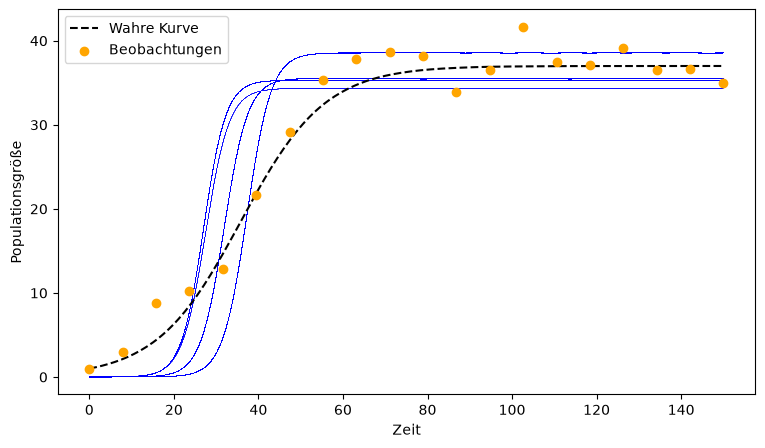

In [ ]:
# Lösung


times_plot = np.linspace(times_data[0], times_data[-1], 200)

plt.figure(figsize=(9, 5))

#eine kurve pro parametersatz
for i in range(samples.shape[1]):
    y0_sample = samples[0, i]
    r_sample = samples[1, i]
    K_sample = samples[2, i]

    predicted = loese_awp(times_plot, y0_sample, r_sample, K_sample)

    plt.plot(times_plot, predicted,color="blue", linewidth=0.1, alpha=0.075)

#wahre parameter
true_curve = loese_awp(times_plot, y0, r, K)
plt.plot(times_plot, true_curve,color="black", linestyle="--", label="True ")

#künstliche messdaten
plt.scatter(times_data, data, color="orange", label="Observed", zorder=3)

plt.xlabel("Time")
plt.ylabel("Populatiom")
plt.legend()
plt.show()

Antwort:  
Die maximale Kapazität der Population wird recht gut getroffen von dwer Vorhersage. Allerdings wird dafür das Wachstum relativ schlecht geschätzt. Es wird deutlich zu steil eingeschätzt.

## Aufgabe 3: Anwendung in mempy  
Jetzt sollen Sie testen, ob Ihr Algorithmus auch in mempy funktioniert. Dafür müssen Sie unten im Bereich        
```python
# ========== Random-Walk-Metropolis ===========
```
Ihren Algorithmus ergänzen. Testen Sie dann, ob Sie damit das GUTS-RED-SD an die UV-B-Daten von Aufgabenblatt 1 fitten können. Schätzen Sie die Vorhersage des Modells kurz ein, insbesondere die Abbildung der Unsicherheit, und vergleichen Sie sie kurz mit der entsprechenden Vorhersage von Blatt 1.

*Hinweis:* Die Datei ```openguts_survival.xlsx``` muss im selben Ordner liegen wie dieses Notebook.

In [ ]:
from mempy import fit, input_data
import mempy
import pandas as pd
import corner

# Eigene Fit-Klasse: Sie erbt alles von mempy.fit.Fit (z.B. pretty_print() und visualize())
# und ergänzt die Methoden my_mcmc(), plot_posterior_predictions() und plot_trace().
class MyFit(fit.Fit):

    def my_mcmc(self, model, exposure_funcs, survival_data, stepsize, hb_fix=False, num_steps=4000, burn_in=2000,
                printres=True, visualize=True, overwrite=False):
        '''
        Fitting via a simple random-walk Metropolis sampler. The chain starts at the best fit of the
        Nelder-Mead-simplex method and uses a uniform prior within the parameter bounds ('min' and 'max' in
        model.params_info).

        Parameters
        ----------
        model: mempy.model.Model
            The bottom level model instance to be fitted
        exposure_funcs: dict
            Dictionary of functions representing the time dependent external exposure
        survival_data: pandas.DataFrame
            The survival_data to which the model should be fitted
        stepsize: list
            Standard deviation of the normally distributed proposal for each free parameter, in the order of
            model.params_info (without the background mortality if hb_fix is True)
        hb_fix: boolean
            Whether or not the background mortality should priorly be fitted solely to the control datasets and subsequently fixed to that value.
        num_steps: int
            The number of steps of the Markov chain
        burn_in: int
            The number of initial steps of the chain that are discarded (at most half of num_steps)
        printres: boolean
            Whether or not the results of this fit should be printed to the console
        visualize: boolean
            Whether or not the model should be plotted with the resulting parameter values
        overwrite: boolean
            Whether or not the results saved in an instance can be overwritten by performing a second fit.
        '''

        self._check_overwrite(overwrite)
        # diese datasets enthalten die unabhängige Variable (Zeit), die Exposition und die beobachteten Überlebensdaten
        # target_density() kann mit ihnen umgehen
        datasets = input_data.create_datasets(exposure_funcs, survival_data) 

        # ==================== Nelder-Mead-Vorfit (Startwerte für die Kette) =======================
        # Ein normaler mempy-Fit liefert die besten Parameterwerte. Dort startet die Markov-Kette, damit sie
        # nicht erst aus einem schlechten Bereich des Parameterraums herauslaufen muss. 
        # Das ist geschummelt, aber nötig, um zuverlässig gute Ergebnisse zu bekommen.
        # Deshalb sollten Sie die Werte aus 'params' als initialen Vorschlag für Ihren Algorithmus nehmen.
        # Mit den richtigen Schrittweiten klappt es theoretisch auch ohne Vorfit. Weil der Algorithmus so simpel ist,
        # sind diese aber schwer zu finden, was unnötig viel Zeit bei der Bearbeitung des Übungsblattes brauchen würde.
        nm_fit = fit.Fit()
        nm_fit.nelder_mead_simplex(model, exposure_funcs, survival_data, hb_fix=hb_fix, printres=False, visualize=False)
        params = nm_fit.params    
        # ==================== Ende des Nelder-Mead-Vorfits ========================================

        # free enthält alle Parameter, die gefittet werden sollen. Wird hb z.B. schon vorher an die Kontrolle gefittet, ist es hier nicht mehr enthalten
        # Das sind also die Parameter, für die Ihr MCMC-Algorithmus Vorschläge machen soll
        free = [p for p, info in model.params_info.items() if info['vary']]

        if hb_fix:
            control_datasets, datasets = input_data.split_control_treatment_dataset(datasets)
            free = [p for p in free if model.params_info[p].get('module') != 'background-mortality']

        if len(stepsize) != len(free):
            raise ValueError(f'stepsize needs one value per free parameter: {free}')

        # Diese Zieldichte bekommt andere Argumente als die Zieldichte des logistischen Wachstums aus Aufgabe 2:
        # Statt der beobachteten Daten und der Zeitpunkte braucht sie die datasets und das Modell,
        # danach wie gewohnt die Parameterwerte.
        def target_density(datasets, model, *values):
            '''
            Calculates the logarithmic target density of a proposed set of values for the free parameters. This is the
            log-likelihood of the model, no prior is calculated. Proposals outside the parameter bounds ('min' and 'max'
            in model.params_info) are rejected by returning NaN, which corresponds to a uniform prior within the bounds.

            Parameters
            ----------
            datasets: list
                The training data in the form of datasets (see input_data.create_datasets())
            model: mempy.model.Model
                The bottom level model instance to be fitted
            *values: float
                The proposed values of the free parameters, in the order of 'free'

            Returns
            ----------
            log_density: float
                The logarithmic likelihood of the proposed parameter values, or NaN if they are outside the bounds
            '''
            trial = params.copy()                    # alle Parameter, fixierte behalten ihren Wert aus dem Vorfit
            for name, value in zip(free, values):    # die freien Parameter durch die vorgeschlagenen Werte ersetzen
                trial[name] = value
            # Liegen alle Parameter innerhalb ihrer Grenzen 'min' und 'max'?
            in_bounds = all(info['min'] <= trial[p] <= info['max'] for p, info in model.params_info.items())
            # mempy berechnet die negative log-Likelihood, deshalb das Minus
            return -model.negloglike(trial, datasets) if in_bounds else np.nan

        # Wie oben schon beschrieben fangen wir mit den schon vorher bestimmten Parameterwerten an, sofern sie variiert werden sollen.
        def initial_state_func():
            return [params[p] for p in free]

        burn_in = min(burn_in,int(num_steps/2)) # Wie viele Samples am Anfang weggeworfen werden

        # ==================== Random-Walk-Metropolis ====================================================
        # Implementieren Sie hier Ihren eigenen Random-Walk-Metropolis-Sampler. Wenn Sie es geschafft haben, dass die Funktion
        # generell funktioniert, dann können Sie sie hier einfach aufrufen. Wenn das nicht klappt, weil doch das eine oder
        # andere gehardcoded ist, dann können Sie aber auch copy-pasten und die Funktion an das GUTS-Problem anpassen.
        # Damit der Rest funktioniert, sollten Ihre Parameter-Samples in der Variable 'samples' liegen und folgende 
        # shape haben: (num_parameters, num_steps - burn_in), also ohne Burn-in
        samples = samples = random_walk_metro(
                                target_density=target_density,
                                target_density_args=(datasets, model),
                                initial_state_func=initial_state_func,
                                num_steps=num_steps,
                                stepsize=stepsize,
                                burn_in=burn_in
                            )
        acceptance_rate = np.mean(np.any(np.diff(samples, axis=1) != 0, axis=0))
        # ==================== Ende des Random-Walk-Metropolis ===========================================

        # Kette als Tabelle mit einer Spalte pro Parameter
        flatchain = pd.DataFrame(samples.T, columns=free)
        
        # Ergebnisse speichern:
        self.method = "my_mcmc (random-walk Metropolis)"
        self.params = {**params, **flatchain.median().to_dict()}     # Schätzwerte: Median der Kette, feste Parameter aus dem Vorfit
        self.params_info = model.params_info
        self.residual = model.negloglike(self.params, datasets)      # negative log-Likelihood bei den Schätzwerten
        
        # Unsicherheiten: feste Parameter haben keine (untere = obere Grenze = Wert) ...
        self.uncertainties = {p: {'lower': v, 'upper': v} for p, v in self.params.items()}
        # ... freie Parameter: 95 %-Intervall aus dem 2,5 %- und 97,5 %-Quantil der Kette
        for p in free:
            self.uncertainties[p] = {'lower': flatchain[p].quantile(0.025), 'upper': flatchain[p].quantile(0.975)}
        self.uncertainties_method = 'my_mcmc'
        self.flatchain = flatchain

        self.fit_info = {
            'n_steps'        : num_steps,
            'burn_in'        : burn_in,
            'acceptance_rate': acceptance_rate,
            'n_vary'         : len(free)
            }
        self.goodness = {
            'nrmse'          : model.nrmse(self.params, exposure_funcs, survival_data, with_akaike = False)
            }
        self.hb_fix = hb_fix
        self.model = model
        self.data = {
            'exposure': exposure_funcs,
            'survival': survival_data
        }
        self.data_info = {
            'num_expos': model.num_expos,
            'num_treatments': len(survival_data),
            'starttime' : survival_data.index[0],
            'endtime' : survival_data.index[-1],
            'num_individuals' : survival_data[survival_data.keys()[0]].iloc[0]
            }

        if printres:
            self.pretty_print()
        if visualize:
            self.visualize()
            # zusätzliche Plots:
            corner.corner(flatchain, labels=free, show_titles=True, quantiles=[0.025, 0.5, 0.975])
            self.plot_posterior_predictions(250)
            self.plot_trace()


    def plot_posterior_predictions(self, n_samples=100):
        '''
        Plots the model solutions for n_samples random parameter sets from the chain (black) and for the
        estimated parameter values (red), arranged like visualize().

        Parameters
        ----------
        n_samples: int
            The number of parameter sets drawn from the chain
        '''
        model, exposure_funcs, survival_data = self.model, self.data['exposure'], self.data['survival']
        n_comps = model._numCLike + model._numSLike
        times = np.linspace(survival_data.index[0], survival_data.index[-1], 200)
        fig, axes = plt.subplots(model.num_expos + n_comps, len(survival_data.columns), sharex=True, sharey='row',
                                 figsize=(3*len(survival_data.columns), 3*(model.num_expos + n_comps)), squeeze=False)

        for col, treat in enumerate(survival_data.columns):
            xc = input_data.get_xc(treat, exposure_funcs)
            y0 = np.zeros(n_comps)
            y0[model._numCLike:] = survival_data[treat].iloc[0]           

            for k, exposure in enumerate(xc):                              
                axes[k, col].plot(times, exposure(times))
            for _, sample in self.flatchain.sample(n_samples).iterrows():  
                params = self.params.copy()
                params.update(sample.to_dict())                            
                y = model._solve(params, y0, times, xc)
                for c in range(n_comps):                                   
                    axes[model.num_expos + c, col].plot(times, y[:, c], color='black', linewidth=0.5, alpha=0.1)
            y = model._solve(self.params, y0, times, xc)                   
            for c in range(n_comps):
                axes[model.num_expos + c, col].plot(times, y[:, c], color='red')
            axes[-1, col].scatter(survival_data.index, survival_data[treat], zorder=3)
            axes[0, col].set_title(treat)

        for row, label in enumerate(list(exposure_funcs) + list(model.comp_info)):
            axes[row, 0].set_ylabel(label)
        plt.tight_layout()
        plt.show()


    def plot_trace(self):
        '''
        Plots the trace of every sampled parameter (chain after the burn-in).
        '''
        self.flatchain.plot(subplots=True, figsize=(10, 2*self.flatchain.shape[1]), color='black', linewidth=0.5, xlabel='step after burn-in')
        plt.show()


Model: RED_SD
Number of exposures: 1

 BEST-FIT PARAMETER VALUES
┏━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃       ┃       kd ┃         b ┃         m ┃         hb ┃
┣━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━━┫
┃ Value ┃ 0.644534 ┃  49.7602  ┃ 0.0247716 ┃ 0.00670168 ┃
┣━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━━┫
┃ lower ┃ 0.270418 ┃   8.60667 ┃ 0.0122543 ┃ 0.00670168 ┃
┣━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━━┫
┃ upper ┃ 3.98697  ┃ 130.41    ┃ 0.0609884 ┃ 0.00670168 ┃
┗━━━━━━━┻━━━━━━━━━━┻━━━━━━━━━━━┻━━━━━━━━━━━┻━━━━━━━━━━━━┛

 FIT-ALGORITHM  INFO
Method: my_mcmc (random-walk Metropolis)
The background mortality was priorly fitted to control-data.
┏━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃   n_steps ┃   burn_in ┃   acceptance_rate ┃   n_vary ┃
┣━━━━━━━━━━━╋━━━━━━━━━━━╋━━━━━━━━━━━━━━━━━━━╋━━━━━━━━━━┫
┃     10000 ┃      2000 ┃          0.209276 ┃        3 ┃
┗━━━━━━━━━━━┻━━━━━━━━━━━┻━━━━━━━━━━━━━━━━━━━┻━━━━━━━━━━┛
Valu

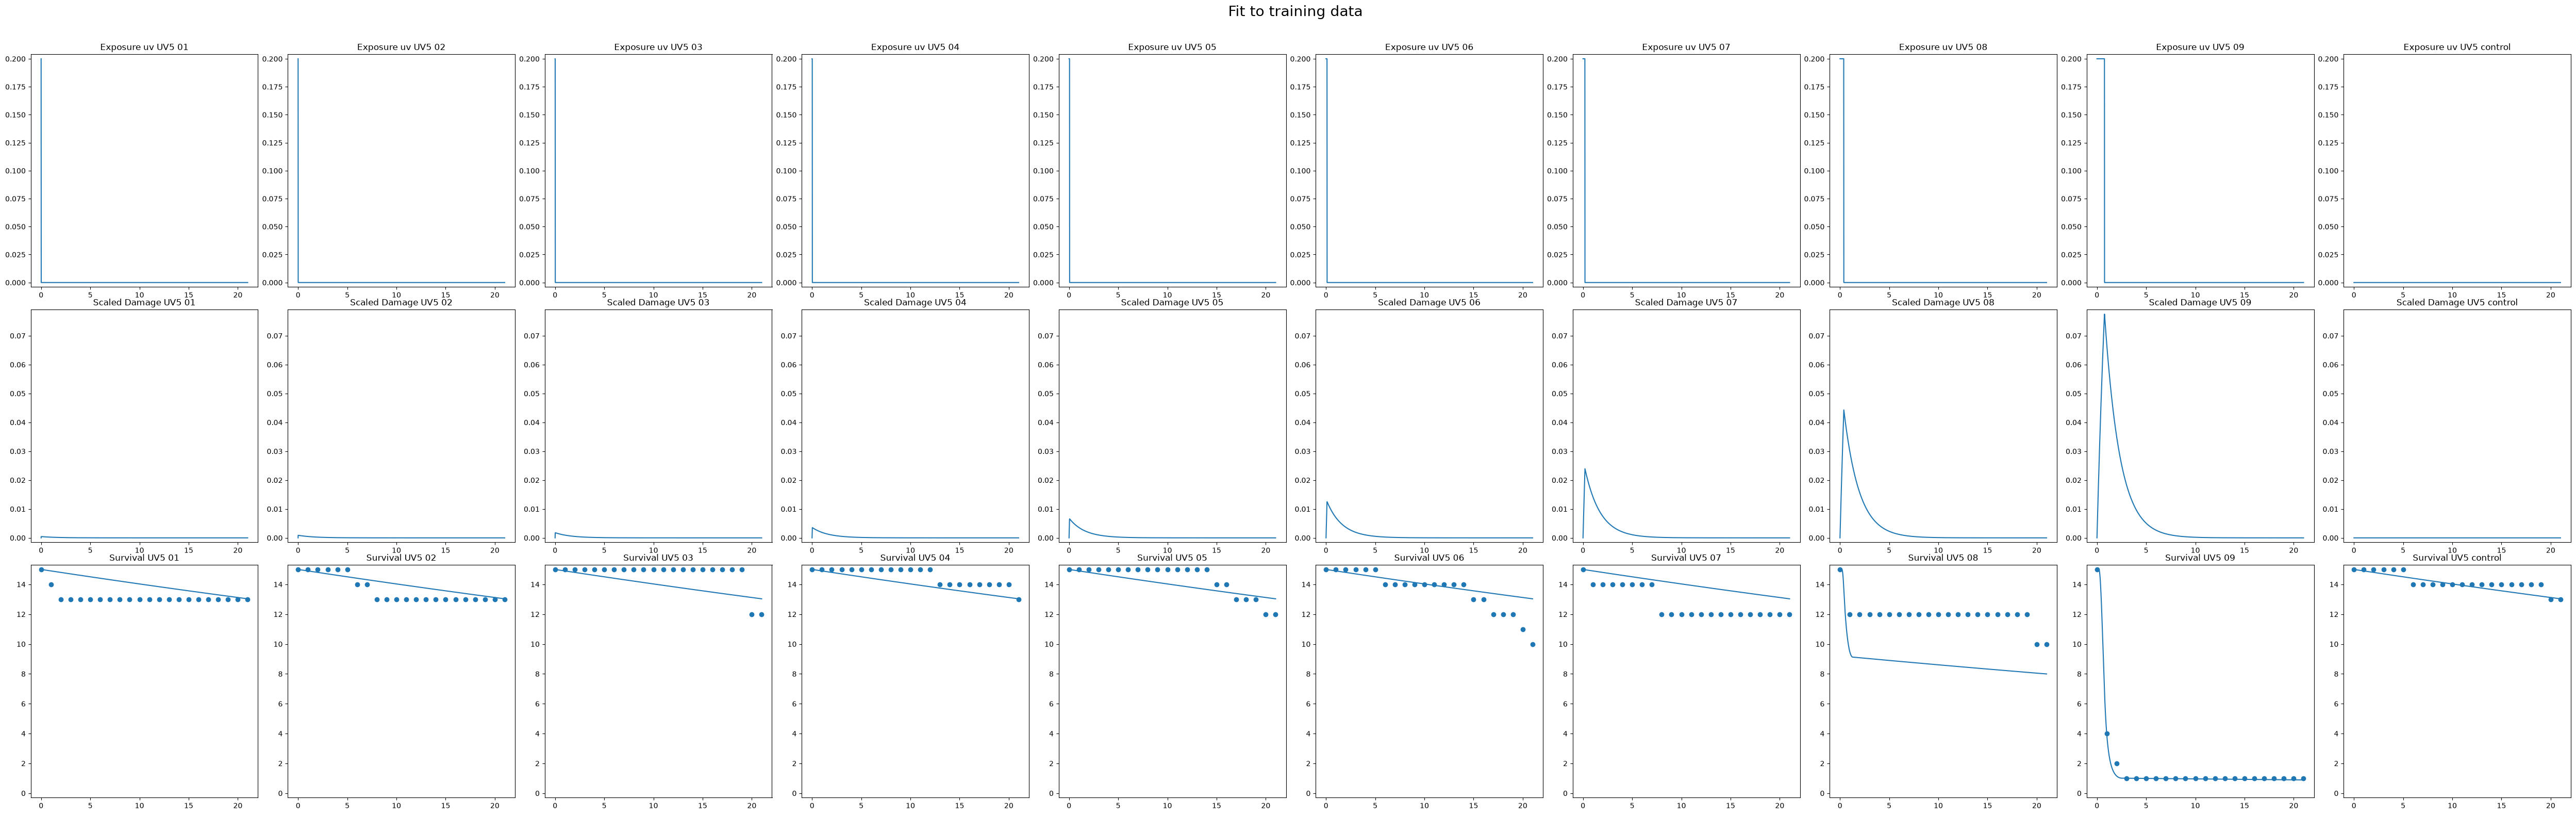

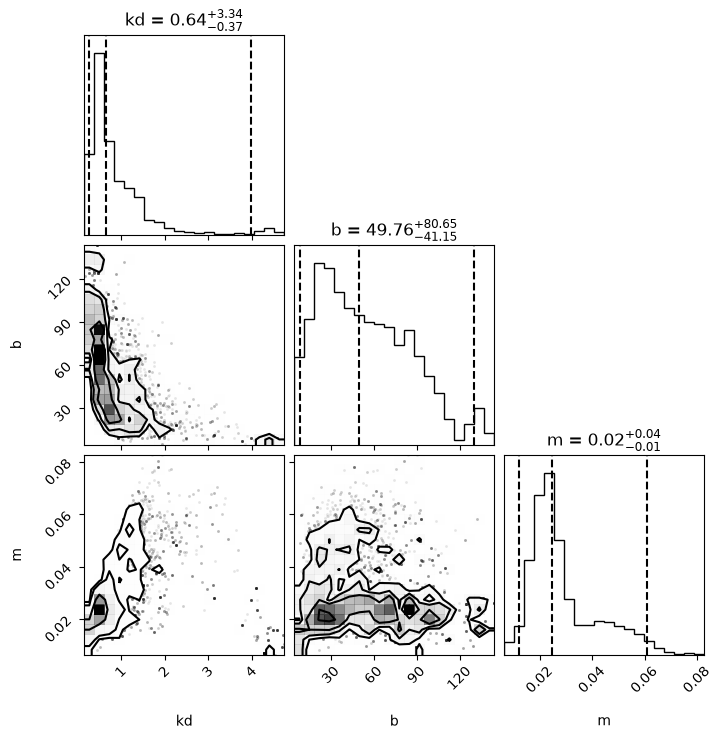

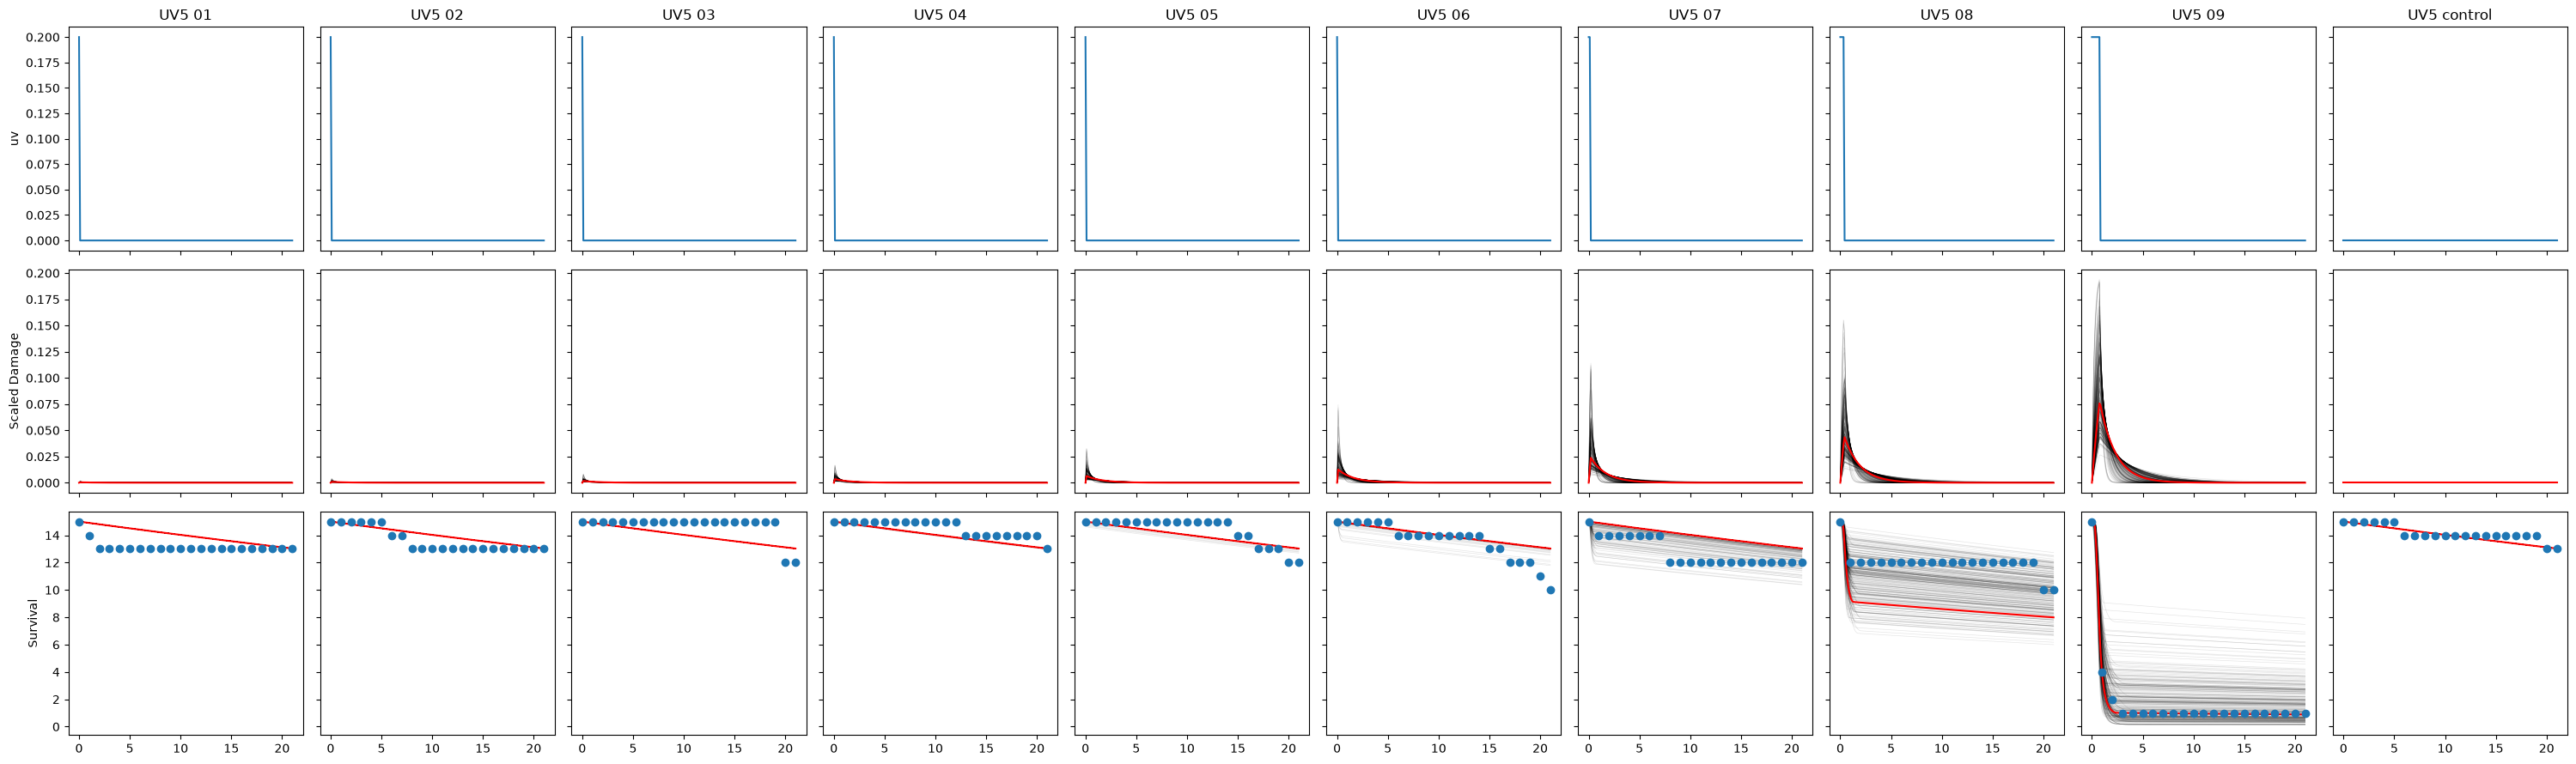

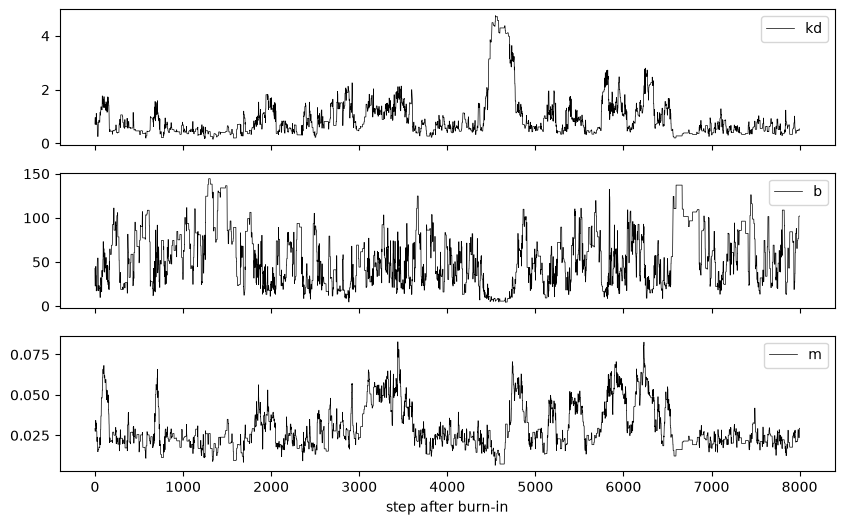

In [ ]:
model = mempy.model.RED_SD()

exposure_funcs, survival_data, num_expos = input_data.read_exposure_survival(
    "", "openguts_survival.xlsx",
    exposure_name="uv",
    survival_name="survival",
    info_name="meta",
    visualize=False
)

my_fit = MyFit()
my_fit.my_mcmc(model, exposure_funcs, survival_data, stepsize=[0.3, 20, 0.005], hb_fix=True, num_steps=10000)   # stepsize for kd, b, m


Antwort: 
Das Modell funktioniert jetzt im Allgemeinen sehr viel besser als in Aufgabenblatt 1. In Bild 1 und 3 lässt sich erkennen, dass bei UV 01-07 die Mortalität allgemein gut eingeschätzt wird. Allerdings wird dabei ein überwiegend langsamer Rückgang vorhergesagt, der zB in 05 und 06 nicht exakt ist. Besonders gut funktioniert dahingegen UV 09, was beei Aufgabenblatt 1 ein größeres Problem darstellte. Bei 08, wird dafür allerdings die Mortalität überschätzt. 
Bei den Unsiccherheiten lässt sich jedoch erkennen, dass bei Bild 3 UV 07-09 die Daten im Unsicherheitsbereich liegen und damit die Prognose erfolgriech war. Bei 01-06 war der Unsicherheitsbereich sher viel kleiner und die Daten lagen nicht darin und konnten nicht korrekt abgebildet werden.

In der Unsicherheit der Parameter kann man erkennen, dass es für alle Parameter einen größeren möglichen Bereich gibt. Außerdem ist zu erkennen, dass sie asymmetrisch sind. Bei kd und b ist zu erkennen, dass sie wahrscheinlich voneinander abhängig sind und deshalb schwer zu beurteilen. 